# N01 — MLP, ewaluacja i optymalizacja (PyTorch)

## Zadanie 1

- Wczytaj MNIST. Proponowany podział to 10 000 obrazów do treningu, 2000 do walidacji i 2000 do testu.
- Walidację wydziel z danych treningowych, a test z oficjalnego zbioru testowego. Żaden obraz nie może należeć do dwóch zbiorów.
- Przeskaluj piksele do zakresu [0, 1] i przygotuj partie danych. Wyświetl liczebności zbiorów i kształty obrazów: 28×28, czyli 784 wartości po spłaszczeniu.
- Sprawdź prosty punkt odniesienia: zawsze przewiduj najczęstszą klasę z treningu i policz odsetek poprawnych odpowiedzi na teście (accuracy).
- Możesz użyć własnych danych, jeśli podasz ich źródło i zachowasz te same zasady podziału.
- Podane ustawienia MLP są przykładowe. Własne architektury i parametry dobieraj z zachowaniem celu zadania oraz zasad porównania.
- Własne ustawienia porównuj na tym samym zbiorze walidacyjnym. Nie używaj testu do wyboru parametrów.

In [1]:
from pathlib import Path
import copy
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import torch
from torch import nn
from torch.utils.data import DataLoader, Subset, TensorDataset
from torchvision import datasets, transforms, models
from IPython.display import display


def show(df):
    acc_cols = [c for c in df.columns if "accuracy" in str(c)]
    display(df.style.format(precision=4).format("{:.2%}", subset=acc_cols))


torch.manual_seed(42)
if torch.cuda.is_available():
    device = "cuda"
elif torch.backends.mps.is_available():  # Apple Silicon GPU
    device = "mps"
else:
    device = "cpu"
print(f"device: {device}")
DATA_ROOT = Path("data")

train_full = datasets.MNIST(DATA_ROOT, train=True, download=True)
test_full = datasets.MNIST(DATA_ROOT, train=False, download=True)

device: mps


In [2]:
N_TRAIN, N_VAL, N_TEST = 10_000, 2_000, 2_000
BATCH_SIZE = 128
split_generator = torch.Generator().manual_seed(42)

# Trening i walidacja to rozłączne fragmenty jednej permutacji oficjalnego treningu;
# test losujemy wyłącznie z oficjalnego zbioru testowego
train_perm = torch.randperm(len(train_full), generator=split_generator)
train_idx = train_perm[:N_TRAIN]
val_idx = train_perm[N_TRAIN:N_TRAIN + N_VAL]
test_idx = torch.randperm(len(test_full), generator=split_generator)[:N_TEST]
assert not set(train_idx.tolist()) & set(val_idx.tolist())


def make_dataset(source, indices):
    # uint8 0–255 -> float32 w [0, 1] (N, 1, 28, 28)
    images = source.data[indices].unsqueeze(1).float() / 255.0
    return TensorDataset(images, source.targets[indices])


train_ds = make_dataset(train_full, train_idx)
val_ds = make_dataset(train_full, val_idx)
test_ds = make_dataset(test_full, test_idx)

train_loader = DataLoader(train_ds, batch_size=BATCH_SIZE, shuffle=True,
                          generator=torch.Generator().manual_seed(42))
val_loader = DataLoader(val_ds, batch_size=BATCH_SIZE)
test_loader = DataLoader(test_ds, batch_size=BATCH_SIZE)

sets_summary = {}
for name, loader in [("trening", train_loader), ("walidacja", val_loader), ("test", test_loader)]:
    x_batch, y_batch = next(iter(loader))
    images = loader.dataset.tensors[0]
    sets_summary[name] = {
        "obrazy": len(loader.dataset),
        "partia: obrazy": tuple(x_batch.shape),
        "partia: etykiety": tuple(y_batch.shape),
        "obraz": tuple(x_batch[0].shape),
        "po spłaszczeniu": x_batch[0].numel(),
        "min piksel": images.min().item(),
        "max piksel": images.max().item(),
    }
show(pd.DataFrame.from_dict(sets_summary, orient="index"))

# Baseline: zawsze najczęstsza klasa z treningu.
y_train = train_ds.tensors[1]
y_test = test_ds.tensors[1]
majority_class = torch.bincount(y_train, minlength=10).argmax().item()
baseline_acc = (y_test == majority_class).float().mean().item()
print(f"baseline: zawsze cyfra {majority_class} -> accuracy na teście {baseline_acc:.3f}")

,obrazy,partia: obrazy,partia: etykiety,obraz,po spłaszczeniu,min piksel,max piksel
trening,10000,"(128, 1, 28, 28)","(128,)","(1, 28, 28)",784,0.0000,1.0000
walidacja,2000,"(128, 1, 28, 28)","(128,)","(1, 28, 28)",784,0.0000,1.0000
test,2000,"(128, 1, 28, 28)","(128,)","(1, 28, 28)",784,0.0000,1.0000


baseline: zawsze cyfra 1 -> accuracy na teście 0.107


Spłaszczenie ma konsekwencję: MLP nie wie, które piksele ze sobą sąsiadują. Dostaje 784 liczby w ustalonej kolejności, więc piksel w wierszu 12 i kolumnie 13 to dla niego cecha numer 349.

## Zadanie 2

- Zbuduj MLP rozpoznający cyfry, przykładowo ze spłaszczeniem obrazu, warstwą 256 neuronów z ReLU i Dropout 0.3. Wyjście musi odpowiadać klasom danych. Nie stosuj softmax na wyjściu: CrossEntropyLoss przyjmuje nieznormalizowane wyniki, czyli logity.
- Na początek: 3 epoki, Adam ze współczynnikiem uczenia 0.001 i partie po 128 obrazów.
- Napisz pętlę treningową z zerowaniem gradientów, backward i aktualizacją wag. Przełączaj model między train i eval; podczas ewaluacji wyłącz gradienty przez no_grad.
- Po każdej epoce zapisz stratę (loss) i accuracy na treningu oraz walidacji. Przy uśrednianiu uwzględnij, że ostatnia partia może być mniejsza.

In [3]:
def build_mlp():
    return nn.Sequential(
        nn.Flatten(),  # (N, 1, 28, 28) -> (N, 784)
        nn.Linear(784, 256),
        nn.ReLU(),
        nn.Dropout(0.3),
        nn.Linear(256, 10),  # 10 logitów; softmax jest wewnątrz CrossEntropyLoss
    )


def train_one_epoch(model, loader, optimizer, loss_fn):
    model.train()
    total_loss, correct, total = 0.0, 0, 0
    for x, y in loader:
        x, y = x.to(device), y.to(device)
        optimizer.zero_grad()
        logits = model(x)
        loss = loss_fn(logits, y)
        loss.backward()
        optimizer.step()
        # loss to średnia w partii; mnożymy przez jej rozmiar, bo ostatnia partia jest mniejsza.
        total_loss += loss.item() * len(y)
        correct += (logits.argmax(dim=1) == y).sum().item()
        total += len(y)
    return total_loss / total, correct / total


@torch.no_grad()  # wyłącza zapamiętywanie obliczeń do gradientów
def evaluate(model, loader, loss_fn):
    model.eval()
    total_loss, correct, total = 0.0, 0, 0
    for x, y in loader:
        x, y = x.to(device), y.to(device)
        logits = model(x)
        total_loss += loss_fn(logits, y).item() * len(y)
        correct += (logits.argmax(dim=1) == y).sum().item()
        total += len(y)
    return total_loss / total, correct / total


def fit(model, optimizer, loss_fn, epochs):
    history = {"train_loss": [], "train_acc": [], "val_loss": [], "val_acc": []}
    for epoch in range(1, epochs + 1):
        train_loss, train_acc = train_one_epoch(model, train_loader, optimizer, loss_fn)
        val_loss, val_acc = evaluate(model, val_loader, loss_fn)
        history["train_loss"].append(train_loss)
        history["train_acc"].append(train_acc)
        history["val_loss"].append(val_loss)
        history["val_acc"].append(val_acc)
    return history


HISTORY_COLUMNS = {"train_loss": ("trening", "loss"), "train_acc": ("trening", "accuracy"),
                   "val_loss": ("walidacja", "loss"), "val_acc": ("walidacja", "accuracy")}


def history_frame(history):
    df = pd.DataFrame(history)
    df.index = pd.RangeIndex(1, len(df) + 1, name="epoka")
    df.columns = pd.MultiIndex.from_tuples([HISTORY_COLUMNS[c] for c in df.columns])
    return df


EPOCHS = 3
torch.manual_seed(42)
mlp = build_mlp().to(device)
optimizer = torch.optim.Adam(mlp.parameters(), lr=0.001)
history = fit(mlp, optimizer, nn.CrossEntropyLoss(), EPOCHS)
show(history_frame(history))

## Zadanie 3

- Porównaj SGD, SGD z momentum i Adam. Przykładowe ustawienia to odpowiednio lr=0.01, lr=0.01 z momentum 0.9 oraz lr=0.001.
- Wybierz wspólną architekturę, dane, wielkość partii i liczbę epok (przykładowo 3). Nie zmieniaj ich między optymalizatorami, żeby porównanie dotyczyło właśnie sposobu uczenia.
- Przed każdą próbą przywróć ten sam zestaw początkowych wag i utwórz nowy optymalizator.
- Zapisz modele w models_by_name, a przebiegi metryk w histories. Porównuj je na walidacji; nie używaj testu do wyboru optymalizatora.

In [4]:
OPTIMIZERS = {
    "SGD": lambda params: torch.optim.SGD(params, lr=0.01),
    "SGD + momentum": lambda params: torch.optim.SGD(params, lr=0.01, momentum=0.9),
    "Adam": lambda params: torch.optim.Adam(params, lr=0.001),
}
#  SGD = Stochastic Gradient Descent
#  Adam = Adaptive Moment Estimation

torch.manual_seed(42)
initial_weights = copy.deepcopy(build_mlp().state_dict())

histories = {}
models_by_name = {}
for name, make_optimizer in OPTIMIZERS.items():
    torch.manual_seed(42)
    train_loader.generator.manual_seed(42)
    model = build_mlp().to(device)
    model.load_state_dict(initial_weights)
    optimizer = make_optimizer(model.parameters())
    histories[name] = fit(model, optimizer, nn.CrossEntropyLoss(), EPOCHS)
    models_by_name[name] = model

results = pd.concat({name: history_frame(h) for name, h in histories.items()}, names=["optymalizator"])
show(results)

show(results.xs(EPOCHS, level="epoka")["walidacja"])

,loss,accuracy
optymalizator,,
SGD,1.6615,73.65%
SGD + momentum,0.3988,88.85%
Adam,0.2773,92.00%


## Zadanie 4

- Na jednym wykresie pokaż accuracy na walidacji dla trzech optymalizatorów. Podpisz osie, zaznacz numery epok i dodaj legendę.
- Narysuj również przebiegi straty na treningu i walidacji.
- Na podstawie wyników walidacyjnych wybierz model z zadania 3 i zapisz go jako best_model.
- Porównaj wykresy: czy niższa strata zawsze oznacza wyższe accuracy?

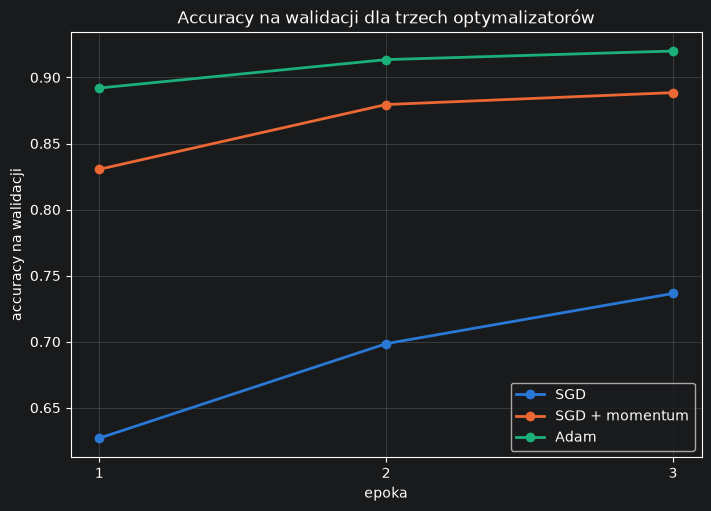

In [5]:
epochs = range(1, EPOCHS + 1)
COLORS = {"SGD": "#2a78d6", "SGD + momentum": "#eb6834", "Adam": "#1baf7a"}

fig_acc, ax_acc = plt.subplots(figsize=(7, 5), constrained_layout=True)
for name, h in histories.items():
    ax_acc.plot(epochs, h["val_acc"], marker="o", linewidth=2, color=COLORS[name], label=name)
ax_acc.set(xlabel="epoka", ylabel="accuracy na walidacji", xticks=list(epochs),
           title="Accuracy na walidacji dla trzech optymalizatorów")
ax_acc.grid(alpha=0.3)
ax_acc.legend();

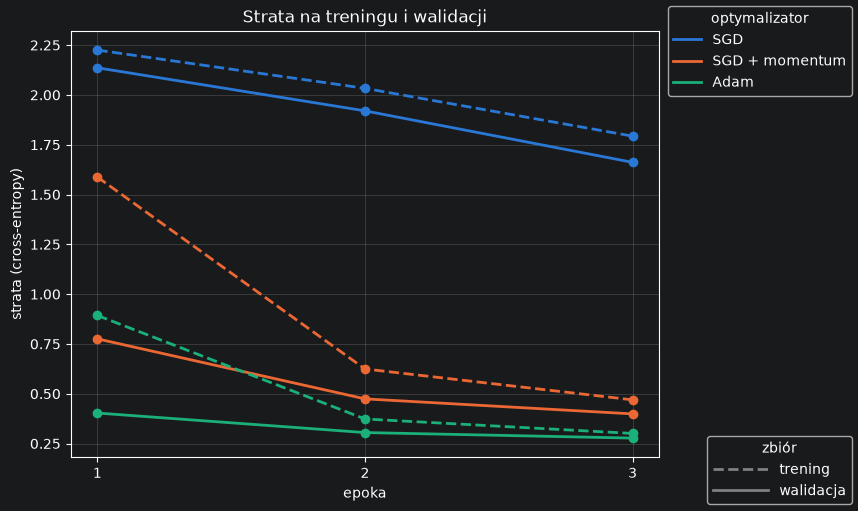

In [6]:
from matplotlib.lines import Line2D

fig_loss, ax_loss = plt.subplots(figsize=(8.5, 5), constrained_layout=True)
for name, h in histories.items():
    ax_loss.plot(epochs, h["train_loss"], marker="o", linewidth=2, linestyle="--", color=COLORS[name])
    ax_loss.plot(epochs, h["val_loss"], marker="o", linewidth=2, color=COLORS[name])
ax_loss.set(xlabel="epoka", ylabel="strata (cross-entropy)", xticks=list(epochs),
            title="Strata na treningu i walidacji")
ax_loss.grid(alpha=0.3)

fig_loss.legend(handles=[Line2D([], [], color=COLORS[name], linewidth=2, label=name) for name in histories],
                title="optymalizator", loc="outside right upper")
fig_loss.legend(handles=[Line2D([], [], color="gray", linewidth=2, linestyle="--", label="trening"),
                         Line2D([], [], color="gray", linewidth=2, label="walidacja")],
                title="zbiór", loc="outside right lower", handlelength=4);

In [7]:
# Wybór wyłącznie według walidacji; models_by_name trzyma modele po ostatniej epoce.
best_name = max(histories, key=lambda name: histories[name]["val_acc"][-1])
best_model = models_by_name[best_name]
print(f"best_model: {best_name} (accuracy na walidacji {histories[best_name]['val_acc'][-1]:.4f})")

best_model: Adam (accuracy na walidacji 0.9200)


**Wybór modelu:** `best_model` to Adam: ma najwyższe accuracy na walidacji po 3 epokach (92.00%) i zarazem najniższą stratę walidacyjną (0.2773).

In [8]:
val_points = results["walidacja"].reset_index()
pairs = val_points.merge(val_points, how="cross", suffixes=(" A", " B"))
show(pairs[(pairs["loss A"] < pairs["loss B"]) & (pairs["accuracy A"] < pairs["accuracy B"])]
     .reset_index(drop=True))

,optymalizator A,epoka A,loss A,accuracy A,optymalizator B,epoka B,loss B,accuracy B
0,SGD + momentum,3,0.3988,88.85%,Adam,1,0.4031,89.20%


**Porównanie wykresów**

- **Co widać na wykresach.** SGD uczy się najwolniej: po 3 epokach ma 73.65% accuracy na walidacji, a jego strata jest wciąż wysoka (1.66). Momentum mocno je przyspiesza (88.85%), a Adam jest najszybszy (92.00%). Na wszystkich krzywych strata spada z epoki na epokę, a accuracy rośnie. Adam prowadzi w każdej epoce, nie tylko w ostatniej, więc wybór `best_model` nie zależy od tego, którą epokę weźmiemy.
- **Czy niższa strata zawsze oznacza wyższe accuracy? Nie zawsze, choć zwykle obie miary się zgadzają.** W tej samej epoce kolejność optymalizatorów według straty i według accuracy jest taka sama, a u każdego optymalizatora spadkowi straty towarzyszy wzrost accuracy. Jedyny wyjątek w tabeli to porównanie różnych modeli na różnych etapach uczenia: SGD + momentum po 3. epoce i Adam po 1. epoce. Różnica jest tam bardzo mała: 0.004 straty i 0.35 p.p. accuracy. Strata obrazu to −ln(P prawidłowej cyfry), a accuracy sprawdza tylko, czy prawidłowa cyfra ma najwyższe P. Dlatego model może obniżyć stratę, bo staje się pewniejszy przy obrazach, które już rozpoznaje, a mimo to mylić się na kilku obrazach, przy których prawidłowa cyfra minimalnie przegrywa z inną.
- **Strata walidacyjna niższa od treningowej.** Na wykresie straty walidacja leży poniżej treningu u wszystkich optymalizatorów. Strata treningowa to średnia z całej epoki, także z partii, przy których model był jeszcze słabszy, a walidację liczymy dopiero po epoce. Do tego podczas treningu działa Dropout, który losowo wyłącza część neuronów, a przy walidacji jest wyłączony.


## Zadanie 5

- Uruchom best_model na teście. Narysuj macierz pomyłek dla 10 cyfr: wiersze oznaczają cyfry prawdziwe, a kolumny przewidziane.
- Pokaż precision, recall, F1-score i support (liczbę przykładów) każdej klasy. Jeśli w obliczeniach pojawi się zerowy mianownik, przyjmij wynik 0.
- Policz średnie macro, nadając każdej klasie jednakową wagę. Macro F1 to średnia F1 klas, a nie F1 obliczone ze średnich precision i recall.
- Dla wybranej cyfry odczytaj TP, FP i FN: poprawne rozpoznania, inne cyfry uznane za nią oraz jej obrazy rozpoznane jako inne cyfry. Oblicz jej metryki samodzielnie i porównaj z raportem.
- Wskaż cyfry z najniższym precision i recall. Znajdź odpowiadające im pomyłki w macierzy. Czy samo accuracy pokazałoby te problemy?
- Dla tej samej cyfry narysuj ROC i policz AUC: wybrana cyfra to klasa pozytywna, pozostałe są negatywne. Użyj prawdopodobieństw, nie numerów przewidzianych klas.
- Macierz i ROC pokaż na osobnych figurach około 7×6 cali; każdemu wykresowi przekaż jego osie. W ROC podpisz FPR/TPR, ustaw zakres [0, 1], dodaj przekątną klasyfikatora losowego i legendę z AUC.

Adam na teście: accuracy 91.70%


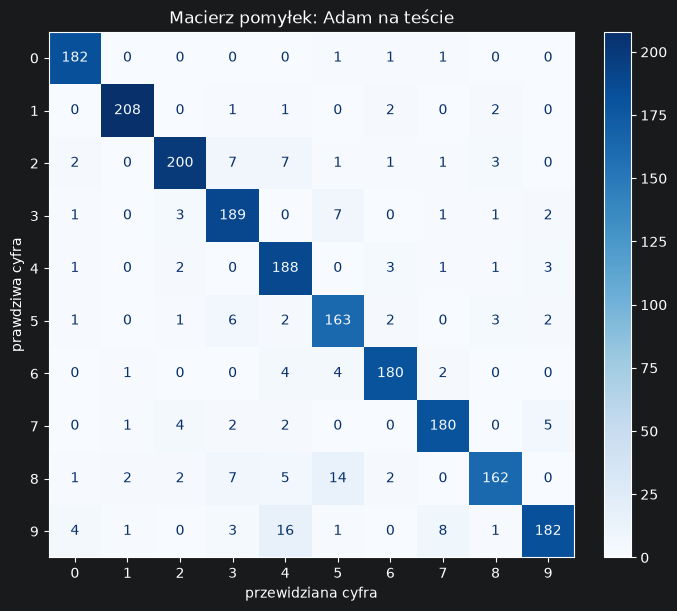

In [9]:
# Prawdopodobieństwa best_model na teście i macierz pomyłek (wiersze: prawdziwe, kolumny: przewidziane).
from sklearn.metrics import (ConfusionMatrixDisplay, confusion_matrix, precision_recall_fscore_support,
                             roc_auc_score, roc_curve)


@torch.no_grad()
def predict(model, loader):
    model.eval()
    probs, labels = [], []
    for x, y in loader:
        probs.append(torch.softmax(model(x.to(device)), dim=1).cpu())
        labels.append(y)
    return torch.cat(probs).numpy(), torch.cat(labels).numpy()


positive_class = 7
probabilities, y_true = predict(best_model, test_loader)
predictions = probabilities.argmax(axis=1)
matrix = confusion_matrix(y_true, predictions, labels=range(10))
print(f"{best_name} na teście: accuracy {(predictions == y_true).mean():.2%}")

fig_cm, ax_cm = plt.subplots(figsize=(7, 6), constrained_layout=True)
ConfusionMatrixDisplay(matrix, display_labels=range(10)).plot(ax=ax_cm, cmap="Blues", values_format="d")
ax_cm.set(xlabel="przewidziana cyfra", ylabel="prawdziwa cyfra", title=f"Macierz pomyłek: {best_name} na teście");

In [10]:
# Precision, recall, F1 i support każdej klasy; przy zerowym mianowniku wynik 0.
precision_per_class, recall_per_class, f1_per_class, support = precision_recall_fscore_support(
    y_true, predictions, labels=range(10), zero_division=0)
report = pd.DataFrame({"precision": precision_per_class, "recall": recall_per_class,
                       "F1": f1_per_class, "support": support}, index=pd.Index(range(10), name="cyfra"))

# Macro: zwykła średnia po klasach, każda cyfra waży tyle samo. Macro F1 to średnia F1 klas.
macro_metrics = report[["precision", "recall", "F1"]].mean()
show(pd.concat([report, pd.DataFrame({**macro_metrics, "support": support.sum()}, index=["macro"])]))

f1_from_macro = 2 * macro_metrics["precision"] * macro_metrics["recall"] / (
            macro_metrics["precision"] + macro_metrics["recall"])
print(f"macro F1 (średnia F1 klas): {macro_metrics['F1']:.4f}; "
      f"F1 z uśrednionych precision i recall: {f1_from_macro:.4f}, to nie to samo")

,precision,recall,F1,support
0,0.9479,0.9838,0.9655,185
1,0.9765,0.9720,0.9742,214
2,0.9434,0.9009,0.9217,222
3,0.8791,0.9265,0.9021,204
4,0.8356,0.9447,0.8868,199
5,0.8534,0.9056,0.8787,180
6,0.9424,0.9424,0.9424,191
7,0.9278,0.9278,0.9278,194
8,0.9364,0.8308,0.8804,195
9,0.9381,0.8426,0.8878,216


macro F1 (średnia F1 klas): 0.9168; F1 z uśrednionych precision i recall: 0.9179, to nie to samo


In [11]:
# TP, FP i FN wybranej cyfry odczytane z macierzy i metryki policzone ręcznie.
tp = matrix[positive_class, positive_class]
fp = matrix[:, positive_class].sum() - tp  # kolumna: inne cyfry uznane za positive_class
fn = matrix[positive_class, :].sum() - tp  # wiersz: obrazy positive_class rozpoznane jako inne cyfry
precision_manual = tp / (tp + fp) if tp + fp else 0.0
recall_manual = tp / (tp + fn) if tp + fn else 0.0
f1_manual = (2 * precision_manual * recall_manual / (precision_manual + recall_manual)
             if precision_manual + recall_manual else 0.0)

show(pd.DataFrame({"TP": [tp], "FP": [fp], "FN": [fn]}, index=[f"cyfra {positive_class}"]))
show(pd.DataFrame({"ręcznie": [precision_manual, recall_manual, f1_manual],
                   "raport": report.loc[positive_class, ["precision", "recall", "F1"]].to_numpy()},
                  index=["precision", "recall", "F1"]))

,TP,FP,FN
cyfra 7,180,14,14


,ręcznie,raport
precision,0.9278,0.9278
recall,0.9278,0.9278
F1,0.9278,0.9278


**Porównanie z raportem:** ręcznie policzone precision, recall i F1 siódemki zgadzają się z raportem. Dla siódemki FP i FN są równe (po 14), dlatego precision i recall wychodzą identyczne (0.9278).

In [12]:
# Najsłabsze cyfry i odpowiadające im pomyłki z macierzy (bez przekątnej, czyli bez trafień).
off_diagonal = matrix.copy()
np.fill_diagonal(off_diagonal, 0)
errors = pd.DataFrame(off_diagonal)  # wiersze: prawdziwe, kolumny: przewidziane
worst_precision = report["precision"].idxmin()
worst_recall = report["recall"].idxmin()


def top_errors(counts, describe):
    return ", ".join(describe(digit, n) for digit, n in counts.nlargest(3).items() if n > 0)


show(pd.DataFrame({
    "cyfra": [worst_precision, worst_recall],
    "wartość": [report.loc[worst_precision, "precision"], report.loc[worst_recall, "recall"]],
    "najczęstsze pomyłki": [
        top_errors(errors[worst_precision], lambda d, n: f"{d} uznane za {worst_precision}: {n}×"),
        top_errors(errors.loc[worst_recall], lambda d, n: f"{worst_recall} uznane za {d}: {n}×"),
    ],
}, index=["najniższe precision", "najniższe recall"]))

,cyfra,wartość,najczęstsze pomyłki
najniższe precision,4,0.8356,"9 uznane za 4: 16×, 2 uznane za 4: 7×, 8 uznane za 4: 5×"
najniższe recall,8,0.8308,"8 uznane za 5: 14×, 8 uznane za 3: 7×, 8 uznane za 4: 5×"


**Najsłabsze cyfry:** najniższe precision ma 4 (0.836): model często uznaje za czwórkę inne cyfry, najczęściej 9 (16 razy), rzadziej 2 (7) i 8 (5). Najniższe recall ma 8 (0.831): mniej więcej co szósta ósemka zostaje rozpoznana jako inna cyfra, najczęściej jako 5 (14 razy) i 3 (7). W macierzy to dwie największe liczby poza przekątną: wiersz 9, kolumna 4 (16) oraz wiersz 8, kolumna 5 (14). Pomyłki nie są symetryczne: 9 jako 4 zdarza się 16 razy, a 4 jako 9 tylko 3 razy. Ta sama komórka macierzy (wiersz 9, kolumna 4) obniża metryki dwóch klas naraz: dla czwórki to FP, więc spada jej precision, a dla dziewiątki FN, więc spada jej recall (0.843, drugie najniższe po ósemce).

**Czy samo accuracy pokazałoby te problemy?** Nie. Accuracy na teście to jedna liczba dla wszystkich cyfr (91.70%). Nie mówi, które cyfry model rozpoznaje gorzej ani z czym je myli. Dopiero metryki dla każdej klasy i macierz pomyłek pokazują, że czwórka i ósemka odstają (ok. 83–84% wobec 97% dla jedynki) i że model myli głównie podobne kształty: 9 z 4 i 8 z 5.

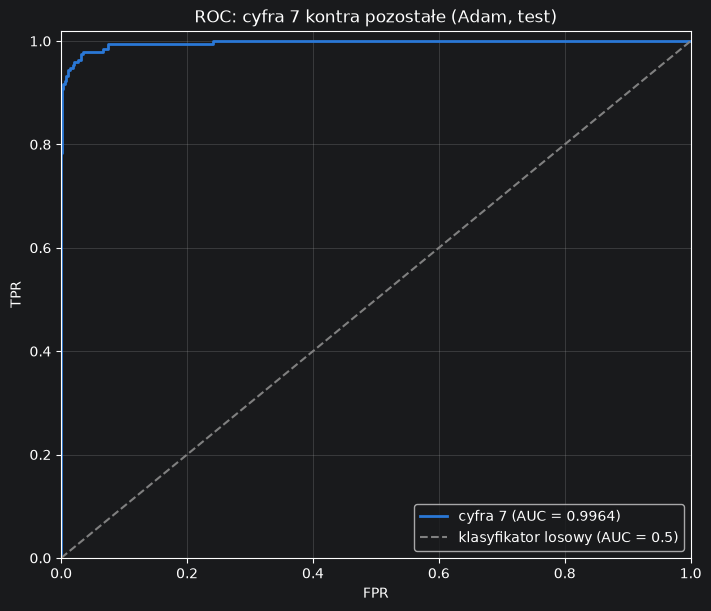

In [13]:
# ROC dla positive_class: klasa pozytywna to ta cyfra, negatywna to pozostałe.
# Wynikiem jest prawdopodobieństwo tej cyfry, a nie numer przewidzianej klasy.
y_binary = (y_true == positive_class).astype(int)
scores = probabilities[:, positive_class]
fpr, tpr, _ = roc_curve(y_binary, scores)
auc = roc_auc_score(y_binary, scores)

fig_roc, ax_roc = plt.subplots(figsize=(7, 6), constrained_layout=True)
ax_roc.plot(fpr, tpr, linewidth=2, color="#2a78d6", label=f"cyfra {positive_class} (AUC = {auc:.4f})")
ax_roc.plot([0, 1], [0, 1], linestyle="--", linewidth=1.5, color="gray", label="klasyfikator losowy (AUC = 0.5)")
ax_roc.set(xlabel="FPR", ylabel="TPR", xlim=(0, 1), ylim=(0, 1.02),
           title=f"ROC: cyfra {positive_class} kontra pozostałe ({best_name}, test)")
ax_roc.grid(alpha=0.3)
ax_roc.legend(loc="lower right");

**ROC i AUC:** AUC dla siódemki wynosi 0.9964. Oznacza to, że jeśli wylosujemy jeden obraz siódemki i jeden obraz innej cyfry, to w 99.6% przypadków model da siódemce wyższe prawdopodobieństwo bycia siódemką. Krzywa przylega do lewego górnego rogu, daleko od przekątnej klasyfikatora losowego (AUC = 0.5).

## Zadanie 6 — Czy można oszukać MLP drobną zmianą obrazu?

- Z walidacji wybierz obraz cyfry, którą best_model rozpoznaje poprawnie. Oblicz gradient cross-entropy względem pikseli tego obrazu, bez aktualizacji wag.
- Utwórz zmienione obrazy metodą FGSM: dodaj epsilon razy znak gradientu i przytnij piksele do [0, 1]. Porównaj kilka wartości epsilon, przykładowo 0, 0.02, 0.05, 0.1, 0.15 i 0.2.
- Dla porównania zmieniaj piksele losowo o +epsilon lub -epsilon i również przytnij je do [0, 1]. Użyj tych samych wartości epsilon.
- Pokaż oryginał, mapę wartości bezwzględnej gradientu, zmieniony obraz i różnicę pikseli. Dla obu metod narysuj prawdopodobieństwo prawdziwej klasy w zależności od epsilon.
- Wypisz przewidziane klasy. Przy jakiej zmianie model zaczyna się mylić? Czy człowiek nadal rozpoznałby cyfrę? Porównaj działanie FGSM z losową zmianą.
- Model nie musi zmienić decyzji. W takim przypadku porównaj, jak mocno spadło prawdopodobieństwo prawdziwej klasy.

In [14]:
def input_loss_gradient(model, image, true_class):
    # Gradient cross-entropy względem pikseli obrazu (1, 28, 28). autograd.grad liczy go tylko dla wejścia:
    # .grad wag zostaje nietknięte, a bez optymalizatora wagi się nie zmieniają.
    model.eval()  # bez Dropout: gradient dotyczy tego samego modelu, który potem ocenia obrazy
    x = image.unsqueeze(0).to(device).requires_grad_(True)
    loss = nn.functional.cross_entropy(model(x), torch.tensor([true_class], device=device))
    (gradient,) = torch.autograd.grad(loss, x)
    return gradient.squeeze(0).cpu()


@torch.no_grad()
def predict_probabilities(model, images):
    # (N, 1, 28, 28) -> (N, 10) prawdopodobieństw klas
    model.eval()
    return torch.softmax(model(images.to(device)), dim=1).cpu()


# Pierwszy obraz z walidacji, który best_model rozpoznaje poprawnie i pewnie. Przy obrazie granicznym
# decyzję zmieniłby już losowy szum, więc porównanie z FGSM niewiele by pokazało.
MIN_CONFIDENCE = 0.99
x_val, y_val = val_ds.tensors
val_probabilities = predict_probabilities(best_model, x_val)
confident = (val_probabilities.argmax(dim=1) == y_val) & (val_probabilities.max(dim=1).values >= MIN_CONFIDENCE)
sample_idx = confident.nonzero()[0].item()
image, true_class = x_val[sample_idx], y_val[sample_idx].item()

EPSILONS = [0, 0.02, 0.05, 0.1, 0.15, 0.2]
gradient = input_loss_gradient(best_model, image, true_class)
# FGSM: krok o epsilon w stronę znaku gradientu, czyli tam, gdzie strata rośnie.
fgsm_images = torch.stack([(image + eps * gradient.sign()).clamp(0, 1) for eps in EPSILONS])
# Porównanie: ta sama wielkość zmiany (±epsilon na piksel), ale znak losowy zamiast znaku gradientu.
random_sign = (torch.randint(0, 2, image.shape, generator=torch.Generator().manual_seed(42)) * 2 - 1).float()
random_images = torch.stack([(image + eps * random_sign).clamp(0, 1) for eps in EPSILONS])

attacks = {"FGSM": fgsm_images, "losowo ±ε": random_images}
attack_probabilities = {name: predict_probabilities(best_model, images) for name, images in attacks.items()}


def attack_summary(images, probabilities):
    return pd.DataFrame({
        "przewidziana cyfra": probabilities.argmax(dim=1).numpy(),
        "P(prawdziwa cyfra)": probabilities[:, true_class].numpy(),
        "norma L2 zmiany": (images - image).flatten(1).norm(dim=1).numpy(),
    }, index=pd.Index([str(eps) for eps in EPSILONS], name="epsilon"))


print(f"obraz nr {sample_idx} z walidacji: cyfra {true_class}, "
      f"P({true_class}) = {val_probabilities[sample_idx, true_class]:.4f}")
show(pd.concat({name: attack_summary(attacks[name], attack_probabilities[name]) for name in attacks}, axis=1))

for name, probabilities in attack_probabilities.items():
    wrong = [eps for eps, p in zip(EPSILONS, probabilities) if p.argmax() != true_class]
    print(f"{name}: " + (
        f"pierwsza pomyłka przy epsilon = {wrong[0]}" if wrong else "model ani razu nie zmienia decyzji"))

obraz nr 1 z walidacji: cyfra 0, P(0) = 0.9982


FGSM: pierwsza pomyłka przy epsilon = 0.15
losowo ±ε: model ani razu nie zmienia decyzji


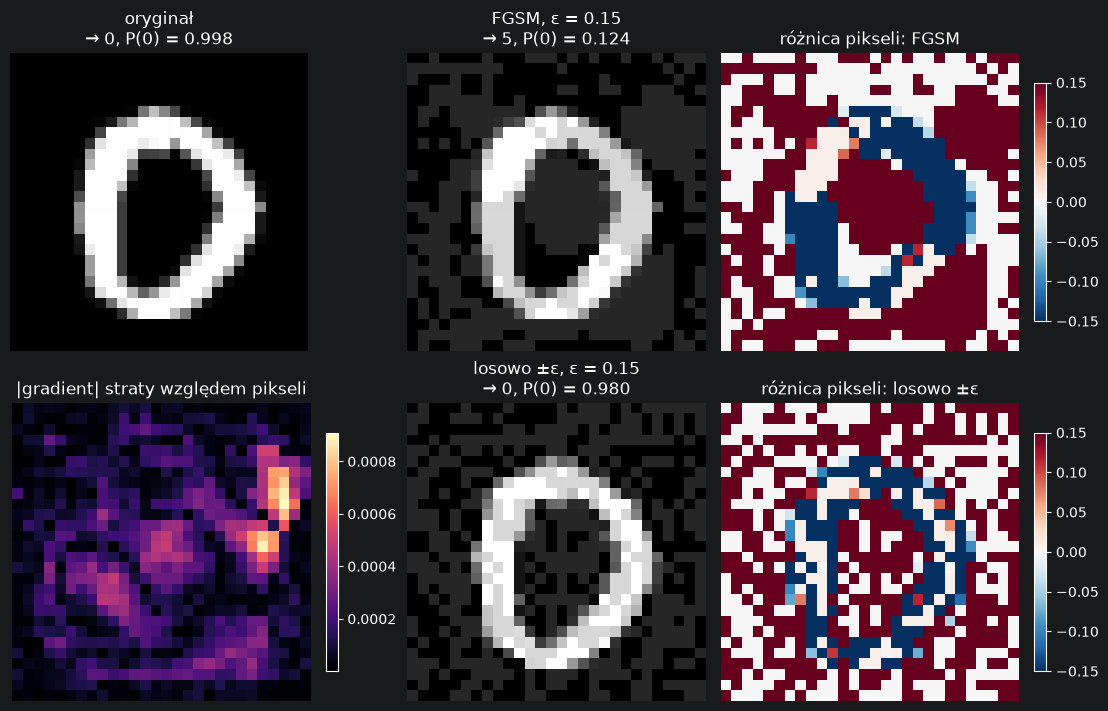

In [15]:
# Szczegóły dla najmniejszego epsilon, przy którym FGSM zmienia decyzję (albo największego, jeśli nie zmienia).
shown = next((i for i, p in enumerate(attack_probabilities["FGSM"]) if p.argmax() != true_class), len(EPSILONS) - 1)
shown_eps = EPSILONS[shown]


def describe(probabilities):
    return f"→ {probabilities.argmax().item()}, P({true_class}) = {probabilities[true_class]:.3f}"


fig_adv, axes = plt.subplots(2, 3, figsize=(11, 7), constrained_layout=True)
axes[0, 0].imshow(image[0], cmap="gray", vmin=0, vmax=1)
axes[0, 0].set_title(f"oryginał\n{describe(val_probabilities[sample_idx])}")
grad_map = axes[1, 0].imshow(gradient[0].abs(), cmap="magma")
axes[1, 0].set_title("|gradient| straty względem pikseli")
fig_adv.colorbar(grad_map, ax=axes[1, 0], shrink=0.8)

for row, name in zip(axes, attacks):
    changed = attacks[name][shown]
    row[1].imshow(changed[0], cmap="gray", vmin=0, vmax=1)
    row[1].set_title(f"{name}, ε = {shown_eps}\n{describe(attack_probabilities[name][shown])}")
    diff_map = row[2].imshow((changed - image)[0], cmap="RdBu_r", vmin=-shown_eps, vmax=shown_eps)
    row[2].set_title(f"różnica pikseli: {name}")
    fig_adv.colorbar(diff_map, ax=row[2], shrink=0.8)
for ax in axes.flat:
    ax.axis("off")

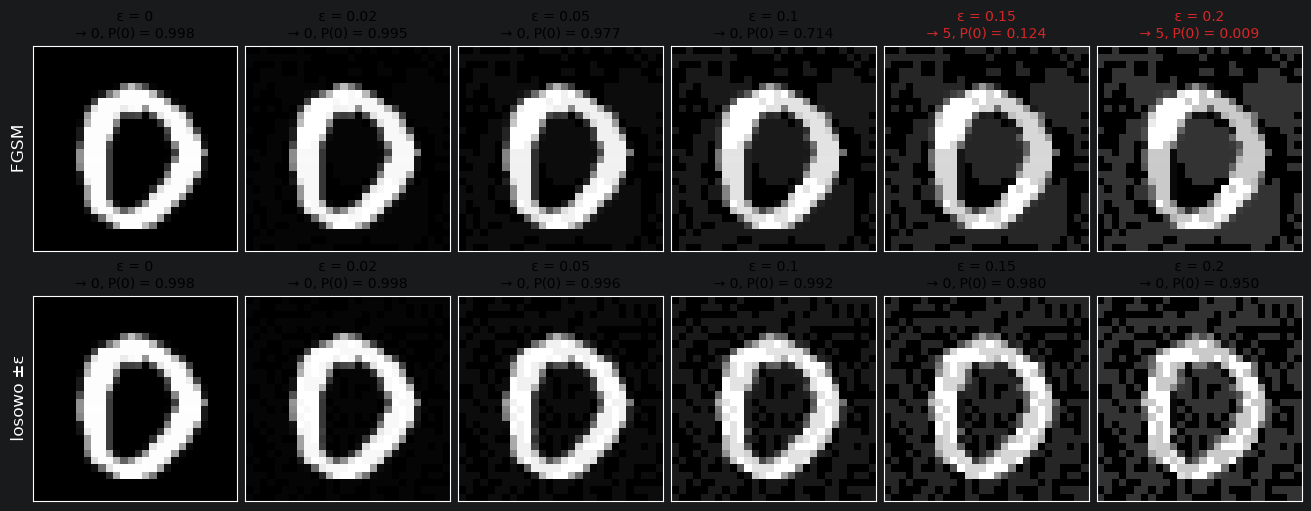

In [16]:
# Zmienione obrazy dla każdego epsilon; czerwony tytuł oznacza błędną decyzję modelu.
fig_grid, axes = plt.subplots(len(attacks), len(EPSILONS), figsize=(13, 5), constrained_layout=True)
for row, name in zip(axes, attacks):
    for ax, eps, changed, probabilities in zip(row, EPSILONS, attacks[name], attack_probabilities[name]):
        ax.imshow(changed[0], cmap="gray", vmin=0, vmax=1)
        ax.set_title(f"ε = {eps}\n{describe(probabilities)}", fontsize=10,
                     color="black" if probabilities.argmax() == true_class else "tab:red")
        ax.set_xticks([])
        ax.set_yticks([])
    row[0].set_ylabel(name, fontsize=12)

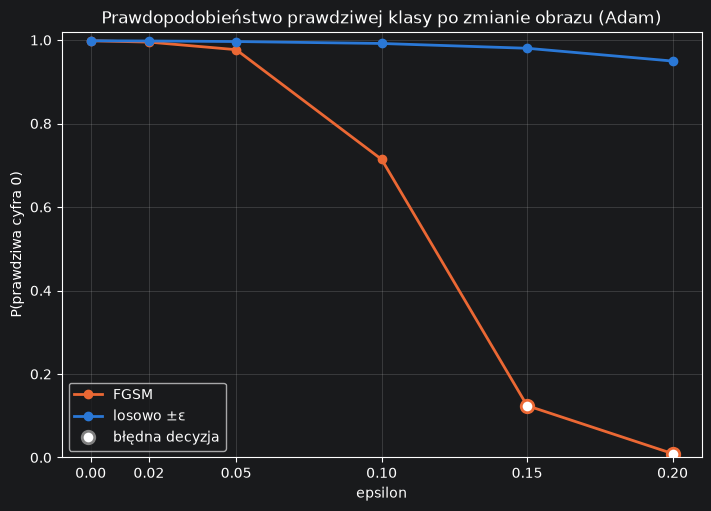

In [17]:
ATTACK_COLORS = {"FGSM": "#eb6834", "losowo ±ε": "#2a78d6"}

fig_prob, ax_prob = plt.subplots(figsize=(7, 5), constrained_layout=True)
for name, probabilities in attack_probabilities.items():
    p_true = probabilities[:, true_class].numpy()
    wrong = probabilities.argmax(dim=1).numpy() != true_class
    ax_prob.plot(EPSILONS, p_true, marker="o", linewidth=2, color=ATTACK_COLORS[name], label=name)
    # Puste znaczniki: model wskazuje już inną cyfrę.
    ax_prob.plot(np.array(EPSILONS)[wrong], p_true[wrong], linestyle="none", marker="o", markersize=9,
                 markerfacecolor="white", markeredgewidth=2, color=ATTACK_COLORS[name])
ax_prob.set(xlabel="epsilon", ylabel=f"P(prawdziwa cyfra {true_class})", xticks=EPSILONS, ylim=(0, 1.02),
            title=f"Prawdopodobieństwo prawdziwej klasy po zmianie obrazu ({best_name})")
ax_prob.grid(alpha=0.3)
ax_prob.legend(handles=ax_prob.get_legend_handles_labels()[0] + [
    Line2D([], [], linestyle="none", marker="o", markersize=9, markerfacecolor="white",
           markeredgewidth=2, color="gray", label="błędna decyzja")]);

**Wybrany obraz:** zero z walidacji (obraz nr 1), które `best_model` (Adam) rozpoznaje z P(0) = 0.9982. Wymagamy pewnej decyzji (P ≥ 0.99), bo przy obrazie granicznym decyzję zmieniłby już losowy szum i porównanie z FGSM niewiele by pokazało.

**Przy jakiej zmianie model zaczyna się mylić?** Przy FGSM model do ε = 0.1 nadal wskazuje 0, ale coraz mniej pewnie: P(0) spada z 0.998 do 0.995, 0.977 i 0.714. Przy ε = 0.15 model myli się i wskazuje 5 (P(0) = 0.124), a przy ε = 0.2 nadal 5 (P(0) = 0.009). Przy losowej zmianie model dla każdego ε wskazuje 0, a P(0) spada tylko do 0.950 przy ε = 0.2.

**Czy człowiek nadal rozpoznałby cyfrę?** Tak. Przy ε = 0.15 i 0.2 zero jest wyraźne: kształt pierścienia się zachował, choć przy FGSM jego lewa i dolna część jest ciemniejsza. Zmianę widać: tło MNIST jest idealnie czarne, więc każde +ε daje szary piksel, a środek zera robi się jaśniejszy. Każdy piksel zmienił się jednak najwyżej o ε, czyli o 0.15 lub 0.2 na skali [0, 1], a to nie zmienia tego, co obraz przedstawia.

**FGSM a losowa zmiana:** obie metody zmieniają każdy piksel o +ε, −ε albo wcale, bo przycięcie do [0, 1] cofa zmianę czarnego tła o −ε i białych pikseli o +ε (dotyczy to ok. 1/3 pikseli). Norma L2 różnicy jest prawie taka sama (przy ε = 0.15: 3.31 dla FGSM i 3.23 dla losowej zmiany). Mimo to przy ε = 0.15 FGSM obniża P(0) do 0.124 i zmienia decyzję, a losowa zmiana tylko do 0.980. Przy tej samej wielkości zmiany o skutku decyduje więc jej kierunek. FGSM dla każdego piksela wybiera znak, który zwiększa stratę, więc wszystkie zmienione piksele działają w tę samą stronę i ich wpływ na logity się sumuje. Przy losowych znakach wpływy w dużej mierze się znoszą. Losową zmianę sprawdziliśmy tylko dla jednego losowania znaków (ziarno 42), więc inne losowanie dałoby nieco inne prawdopodobieństwa. Całe porównanie dotyczy też jednego obrazu zera; dla innych obrazów i innych cyfr ε potrzebne do pomyłki może być inne. Mapa różnic pokazuje, co robi FGSM: rozjaśnia wnętrze zera i przyciemnia dużą część pierścienia, zwłaszcza po lewej stronie i u dołu. Mapa |gradientu| jest największa tuż za prawą krawędzią zera i w jego środku, ale gradient nie jest zerowy nigdzie, także w tle. FGSM bierze tylko znak gradientu, więc zmienia o pełne ε również piksele, na które model reaguje słabo.

**Spadek prawdopodobieństwa bez zmiany decyzji:** losowa zmiana nie zmieniła decyzji przy żadnym ε. Nawet przy ε = 0.2 P(0) spadło tylko o 0.049 (z 0.998 do 0.950). FGSM przy dwa razy mniejszym ε = 0.1 też jeszcze nie zmienia decyzji, ale obniża P(0) o 0.284 (do 0.714), czyli prawie sześć razy mocniej. Odporność na losowy szum nie oznacza więc odporności na zmianę dobraną celowo na podstawie gradientu.